# **Start Section:**

In [1]:
# FIX K1: same notebook runs on Google Colab (Drive) or Kaggle (internet on).
# On Kaggle the working dir is /kaggle/working, so the original "./drive/MyDrive/..." paths
# below are reused unchanged; the dataset is copied there as train.csv / test.csv.
import os, glob, shutil
IN_KAGGLE = os.path.exists("/kaggle/working")
if IN_KAGGLE:
    _data_dir = "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/data"
    os.makedirs(_data_dir, exist_ok=True)
    shutil.copy(glob.glob("/kaggle/input/**/d03_a.csv", recursive=True)[0], f"{_data_dir}/train.csv")  # streamflow train
    shutil.copy(glob.glob("/kaggle/input/**/d03_b.csv", recursive=True)[0], f"{_data_dir}/test.csv")   # streamflow test
    print("Kaggle: streamflow data copied to", _data_dir)
else:
    from google.colab import drive
    drive.mount('/content/drive')


Kaggle: streamflow data copied to ./drive/MyDrive/Regression/streamflow_uncertainty_analysis/data


In [2]:
# FIX K1: original Colab install block kept as-is (runs only on Colab).
# On Kaggle: install only the packages the Kaggle image lacks, pinned to the Colab versions,
# and do NOT restart the kernel.
if IN_KAGGLE:
    !pip install -q optuna==4.6.0 optunahub==0.4.0 cmaes==0.12.0 xgboost==3.1.2 catboost==1.2.8 gpboost==1.6.1 ngboost==0.5.8 pgbm==2.2.0 pytorch-tabnet2==4.5.3 interpret==0.7.4 lime==0.2.0.1 bayesian-optimization==3.2.0 properscoring==0.1 XlsxWriter==3.2.9 mapie==0.6.0 puncc==0.8.0
else:
    import os
    os.environ["PIP_CONSTRAINT"] = "/tmp/numpy_constraint.txt"
    !echo "numpy==1.26.4" > /tmp/numpy_constraint.txt

    !pip uninstall -y torch torchaudio torchvision \
        torchao torchcodec torchdata torchtune torchsummary -q 2>/dev/null

    !pip uninstall -y tensorflow tensorflow-text tensorflow-hub tf-keras \
        tensorflow_decision_forests tensorflow-probability \
        tensorflow-Datasets tensorflow-metadata -q 2>/dev/null

    !pip uninstall -y numpy scikit-learn shap xgboost lightgbm dask \
        seaborn plotly openpyxl Cython catboost interpret lime -q 2>/dev/null

    !pip install numpy==1.26.4 -q
    !pip install scikit-learn==1.6.1 -q
    !pip install torch==2.9.0 -q

    !pip install lightgbm==4.6.0 -q
    !pip install xgboost==3.1.2 -q
    !pip install catboost==1.2.8 -q
    !pip install gpboost==1.6.1 -q
    !pip install ngboost==0.5.8 -q
    !pip install pgbm==2.2.0 -q
    !pip install pytorch-tabnet2==4.5.3 -q

    !pip install bayesian-optimization==3.2.0 -q
    !pip install optuna==4.6.0 -q
    !pip install optunahub==0.4.0 -q
    !pip install cmaes==0.12.0 -q

    !pip install shap==0.44.0 -q
    !pip install lime==0.2.0.1 -q
    !pip install interpret==0.7.4 -q

    !pip install mapie==0.6.0 -q
    !pip install puncc==0.8.0 -q
    !pip install skorch==1.3.1 -q
    !pip install properscoring==0.1 -q

    !pip install dask[dataframe]==2025.12.0 -q
    !pip install cython==3.0.12 -q
    !pip install seaborn==0.13.2 -q
    !pip install plotly==5.24.1 -q
    !pip install kaleido==1.2.0 -q
    !pip install openpyxl==3.1.5 -q
    !pip install XlsxWriter==3.2.9 -q
    !pip install cp==2020.12.3 -q

    !pip install numpy==1.26.4 --force-reinstall --no-deps -q

    os._exit(0)


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


# **Imports**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.svm import SVR
import ngboost
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from gpboost import GPBoostRegressor
from ngboost import NGBRegressor
import optuna
import optunahub
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from interpret import show
from interpret.blackbox import LimeTabular, ShapKernel
from optuna.samplers import RandomSampler
import random
import time
from ngboost.distns import Normal
from ngboost.scores import LogScore
from scipy.stats import norm
from optuna.samplers import BaseSampler
from optuna.samplers import GridSampler
from optuna.samplers import TPESampler
from optuna.samplers import PartialFixedSampler
from optuna.samplers import CmaEsSampler
from optuna.samplers import QMCSampler
from optuna.samplers import NSGAIIISampler
from optuna.samplers import NSGAIISampler
from optuna.samplers import BruteForceSampler
from optuna.samplers import GPSampler
from interpret import set_visualize_provider
from interpret.provider import InlineProvider
from interpret.glassbox import ExplainableBoostingRegressor
from interpret import show
import plotly.express as px
from io import BytesIO
from openpyxl import Workbook, load_workbook
import os
import properscoring as ps
import io
from openpyxl.drawing.image import Image as openpyxlImage
import warnings
import xlsxwriter
from openpyxl.drawing.image import Image
from pgbm.sklearn import HistGradientBoostingRegressor
import torch
from pgbm.torch import PGBM
import plotly.graph_objects as go
warnings.filterwarnings('ignore')
import pickle
import json
from mapie.subsample import Subsample
from sklearn.model_selection import PredefinedSplit  # FIX M3


def _split_cv(n, seed, calib_fraction=0.5):
    """FIX B9: one fit / calibration split (split conformal) written as a PredefinedSplit, because
    MAPIE 0.6 accepts only BaseCrossValidator objects and rejects ShuffleSplit.
    A seeded random half of the training rows is used for calibration."""
    import numpy as _np
    fold = -_np.ones(n, dtype=int)                      # -1 = used to fit the model
    fold[_np.random.RandomState(seed).permutation(n)[: int(round(calib_fraction * n))]] = 0   # 0 = calibration
    return PredefinedSplit(fold)
from mapie.regression import MapieRegressor
from deel.puncc.metrics import regression_sharpness, regression_mean_coverage
from deel.puncc.api.prediction import BasePredictor, DualPredictor
from deel.puncc.regression import SplitCP, CVPlus, CQR
from deel.puncc.plotting import plot_prediction_intervals
from sklearn.model_selection import train_test_split
from typing_extensions import TypedDict
from typing import Union
from mapie.metrics import regression_coverage_score
from sklearn.model_selection import KFold
from PIL import Image as PImage
from openpyxl.utils.dataframe import dataframe_to_rows
from pytorch_tabnet import TabNetRegressor

[1/2] c++ -MMD -MF splitgain_cpu.o.d -DTORCH_EXTENSION_NAME=split_decision -DTORCH_API_INCLUDE_EXTENSION_H -isystem /usr/local/lib/python3.13/dist-packages/torch/include -isystem /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/api/include -isystem /usr/include/python3.13 -fPIC -std=c++17 -c /usr/local/lib/python3.13/dist-packages/pgbm/torch/splitgain_cpu.cpp -o splitgain_cpu.o 


[2/2] c++ splitgain_cpu.o -shared -L/usr/local/lib/python3.13/dist-packages/torch/lib -lc10 -ltorch_cpu -ltorch -ltorch_python -o split_decision.so


I0000 00:00:1795378833.764799      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795378850.154160      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
# Go to find & replace button and replace (streamflow_uncertainty_analysis) with your folder name. Rename your train and test Dataset as train.csv and test.csv.
# Modify the names of the feature in the below cell.
# Replace (str) with actual data label name.

In [5]:
feature_names = ['pH', 'Salinity', 'Turbidity ', 'Water Temperature']
TARGET_LABEL = 'TDS'  # FIX B12: target name used in plot labels (was 'str', the concrete dataset's target, on every dataset)

In [6]:
train_data_path = "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/data/train.csv"
test_data_path = "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/data/test.csv"
train_data = pd.read_csv(train_data_path)
test_data = pd.read_csv(test_data_path)
print("Training data loaded successfully.")
print("Test data loaded successfully.")

Training data loaded successfully.
Test data loaded successfully.


In [7]:
print("\nShape of training data:", train_data.shape)
print("First 5 rows of training data:\n", train_data.head(5))
print("\nShape of test data:", test_data.shape)
print("First 5 rows of test data:\n", test_data.head(5))


Shape of training data: (192, 5)
First 5 rows of training data:
     pH  Salinity  Turbidity   Water Temperature  TDS
0  7.6       0.2         3.0               19.9  290
1  7.4       0.1         0.5               20.7  120
2  7.3       0.2        10.7               23.6  200
3  8.0       0.1         3.0               27.0   94
4  7.8       0.4         1.4               28.4  330

Shape of test data: (96, 5)
First 5 rows of test data:
     pH  Salinity  Turbidity   Water Temperature  TDS
0  7.2       0.1         9.1               18.8  160
1  7.4       0.2         3.7               26.3  190
2  7.0       0.1         3.0               21.6  180
3  8.1       0.1         2.2               17.2  110
4  7.9       0.1        14.1               27.0  200


In [8]:
X_train = train_data.iloc[:, :-1]
y_train = train_data.iloc[:, -1]
X_test = test_data.iloc[:, :-1]
y_test = test_data.iloc[:, -1]
# FIX D4 / D5 (approved 2026-11-22): settings that follow the test-set size
N_BINS = max(2, min(10, len(y_test) // 10))  # D4: bins for binned metrics (was 10 on every dataset; pile: 2-3 points per bin)
COP_T_BURNIN = min(50, len(y_test) // 2)  # D5: COP burn-in (was 50, so with < 50 test points COP's correction never started)
x_test= X_test
print("\nShape of X_train:", X_train.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_test:", y_test.shape)


Shape of X_train: (192, 4)
Shape of y_train: (192,)
Shape of X_test: (96, 4)
Shape of y_test: (96,)


In [9]:
# Apply z-score normalization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Print the first five rows of the normalized data
print("\nFirst five rows of normalized X_train:")
print(X_train[:5])

print("\nFirst five rows of normalized X_test:")
print(X_test[:5])


First five rows of normalized X_train:
[[-0.1272241   0.06262254 -0.51513341 -1.14481478]
 [-0.57957647 -0.38434874 -0.6817983  -0.97088446]
 [-0.80575265  0.06262254 -0.00180554 -0.34038706]
 [ 0.77748062 -0.38434874 -0.51513341  0.39881678]
 [ 0.32512826  0.95656508 -0.62179894  0.70319483]]

First five rows of normalized X_test:
[[-1.03192883 -0.38434874 -0.10847107 -1.38396896]
 [-0.57957647  0.06262254 -0.46846724  0.24662775]
 [-1.48428119 -0.38434874 -0.51513341 -0.77521285]
 [ 1.00365681 -0.38434874 -0.56846617 -1.73182959]
 [ 0.55130444 -0.38434874  0.22485872  0.39881678]]


# **Functions:**

In [10]:
# Define the model classes
model_classes = {
    'Random Forest': RandomForestRegressor,
    'Gradient Boosting': GradientBoostingRegressor,
    'XGBoost': XGBRegressor,
    'LightGBM': LGBMRegressor,
    'GPBoost': GPBoostRegressor,
    'CatBoost': CatBoostRegressor,
    'HistGradientBoosting': HistGradientBoostingRegressor,
    'TabNet': TabNetRegressor,
    'NGBoost': NGBRegressor
}

def _ensure_excel_file(path):
    import os
    import pandas as pd
    if not os.path.exists(path):
        parent = os.path.dirname(path)
        if parent:
            os.makedirs(parent, exist_ok=True)
        pd.DataFrame().to_excel(path)
    return path

In [11]:
def get_best_model_params(results, model_name):
    # Map model names to dictionary keys, assuming keys are strings like 'XGBoost' and not objects
    model_keys = {
        'LightGBM': 'LightGBM',
        'XGBoost': 'XGBoost',
        'GPBoost': 'GPBoost',
        'NGBoost': 'NGBoost',
        'GradientBoosting': 'Gradient Boosting',
        'HGBR' : 'HistGradientBoosting',
        'CatBoost' : 'CatBoost',
        'TabNet' : 'TabNet',
        'PGBM' : 'PGBM'
    }

    # Ensure the requested model name is valid
    if model_name not in model_keys:
        raise ValueError(f"Model name '{model_name}' is not recognized. Available models are: {list(model_keys.keys())}")

    # Filter out entries for the specified model
    model_entries = {key: value for key, value in results.items() if key[0] == model_keys[model_name]}

    # Find the entry with the best (lowest) 'best_score'
    best_entry_key, best_entry_value = min(model_entries.items(), key=lambda item: item[1]['best_score'])

    # Return the best hyperparameters
    return best_entry_value['best_params']

In [12]:
# FIX M4: one miscoverage level for every method in this notebook (MAPIE and PUNCC).
# Was: MAPIE used 0.05 and PUNCC 0.1, so their coverages/widths could not be compared.
ALPHA = 0.1   # target coverage = 1 - ALPHA = 90%


In [13]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test.to_numpy()[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test.to_numpy()[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.to_numpy().ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE(model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path):
    """
    Train and plot conformal prediction intervals using different strategies and save the plots and
    table of ymin/ymax/y_pred to different worksheets in an Excel file for each strategy.

    Parameters:
    - model_class: The class of the model to be used (e.g., LGBMRegressor).
    - best_params: Dictionary of best parameters for the model.
    - X_train: Training features.
    - y_train: Training target.
    - X_test: Test features.
    - y_test: Test target.
    - model_name: Name of the model for labeling purposes.
    - excel_file_path: Path to the Excel file where the plots will be saved.
    """
    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    # Define miscoverage
    MISCOVERAGE: float = ALPHA  # FIX M4: was 0.05  # MISCOVERAGE = alpha # CONFIDENCE = 1-alpha
    warnings.filterwarnings("ignore")  # to suppress them

    # Create output directory
    os.makedirs('output/regression', exist_ok=True)

    # Define strategies and parameters
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Define base estimators
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    # Train strategies using MAPIE
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred) # Corrected line: Removed y_test
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test.to_numpy() - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the results for the test set
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names) * 3 + 1 + len(_strategies) # Strategy plots + Goodness plots + Width plots + Comparison plot + Coverage vs Width plots
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))

    plot_index = 0 # Keep track of the current plot index

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot for comparison
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet for the plots
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = 'conformal_predictions_MAPIE'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        all_rows = []
        y_true_np = y_test.to_numpy().ravel()  # To save multiple conversions
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()



In [14]:
# FIX M1: Conformalized Quantile Regression (Romano et al. 2019) needs models of the
# alpha/2 and 1-alpha/2 QUANTILES. Was: both "quantile" models were the same mean model, so the
# band was mean +/- a constant (split conformal with extra steps), not CQR.
# QuantileModel fits each base model at quantile level q in the way that model supports:
#   native quantile loss  - LightGBM, GPBoost, XGBoost, sklearn GradientBoosting, CatBoost, TabNet
#   predictive distribution - NGBoost (ppf), PGBM (sampled forecasts), pgbm HistGradientBoosting (mean, std)
from scipy.stats import norm as _norm
from sklearn.base import BaseEstimator, RegressorMixin


class QuantileModel(BaseEstimator, RegressorMixin):
    def __init__(self, model_class, params, q):
        self.model_class = model_class
        self.params = params
        self.q = q

    def _kind(self):
        return self.model_class.__name__

    def fit(self, X, y):
        p, q, name = dict(self.params or {}), self.q, self._kind()
        X_ = np.asarray(X)
        y_ = np.asarray(y).ravel()
        if name in ("LGBMRegressor", "GPBoostRegressor"):
            p.update(objective="quantile", alpha=q)
        elif name == "XGBRegressor":
            p.update(objective="reg:quantileerror", quantile_alpha=q)
        elif name == "GradientBoostingRegressor":
            p.update(loss="quantile", alpha=q)
        elif name == "CatBoostRegressor":
            p.pop("objective", None)
            p.update(loss_function=f"Quantile:alpha={q}")
        if "TabNet" in name:
            import torch as _torch

            def _pinball(y_pred, y_true):
                e = y_true - y_pred
                return _torch.mean(_torch.maximum(q * e, (q - 1) * e))
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_, loss_fn=_pinball)
        else:
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_)
        return self

    def predict(self, X):
        X_, q, name = np.asarray(X), self.q, self._kind()
        if name == "NGBRegressor":
            return np.asarray(self.model_.pred_dist(X_).ppf(q)).ravel()
        if name == "PGBMWrapper":
            samples = self.model_.model.predict_dist(X_)
            samples = samples.cpu().numpy() if hasattr(samples, "cpu") else np.asarray(samples)
            return np.quantile(samples, q, axis=0).ravel()
        if name == "HistGradientBoostingRegressor":   # pgbm.sklearn: probabilistic HGBR
            mu, sd = self.model_.predict(X_, return_std=True)
            return (np.asarray(mu) + np.asarray(sd) * _norm.ppf(q)).ravel()
        return np.asarray(self.model_.predict(X_)).ravel()


In [15]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC(
    X_train, y_train, X_test, y_test, best_scores_autosampler, model_class,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Determine the default parameters for the model, or use provided ones
    if model_params is None:
        if model_class.__name__ == 'LGBMRegressor':
            model_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
        else:
            model_params = {}

    # Initialize and train the model using the provided class and parameters
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_test, y_test, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test, y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Wrap the model in a BasePredictor
    base_predictor = BasePredictor(model, is_trained=True)

    # Initialize and fit the SplitCP conformal predictor
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)

    # Compute prediction intervals and metrics on the test set using SplitCP
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for SplitCP
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))

    axs[0].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Initialize and fit the CVPlus conformal predictor
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)

    # Compute prediction intervals and metrics on the test set using CVPlus
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, cvplus, alpha)
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CVPlus - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CVPlus
    axs[1].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Split the training data into proper training (fit) set and calibration set
    X_fit, X_calib, y_fit, y_calib = train_test_split(
        X_train, y_train, test_size=0.5, random_state=0
    )

    # Fit the upper and lower quantile models
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)

    _ = upper_quantile_model.fit(X_fit, y_fit)
    _ = lower_quantile_model.fit(X_fit, y_fit)

    # Wrap the upper and lower quantile models in a dual predictor
    dualpredictor = DualPredictor(
        [lower_quantile_model, upper_quantile_model], is_trained=[True, True]
    )

    # Initialize the CQR conformal predictor
    cqr = CQR(
        dualpredictor, train=False
    )  # train=False to use the pre-trained dual predictor

    # Compute nonconformity scores on the calibration set
    cqr.fit(X_calib=X_calib, y_calib=y_calib)

    # Compute prediction intervals and metrics on the test set
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness, coverage = evaluate_cp(X_test, y_test, cqr, alpha)

    print(f"CQR - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CQR - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CQR
    axs[2].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    # Save all plots and values to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

In [16]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis(
    X_train,
    y_train,
    X_test,
    y_test,
    model_cls,
    model_params,
    excel_file_path=None,
    suptitle: str = "Prediction Intervals"
) -> None:
    # Initialize and fit the model with MAPIE using provided parameters
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    # Visualization function
    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [y_train.min(), y_train.max()],
            [y_train.min(), y_train.max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        y_test,
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        mapie = MapieRegressor(mdl, **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_2')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

# **Tuned Parameters**

In [17]:
# FIX K2: load the tuning results saved by hyperparameter_tuning/Optuna_autosampler.ipynb
# (was: a hand-pasted copy of an older tuning run that had been selected on the TEST set).
import pickle
if IN_KAGGLE:
    _bp = glob.glob("/kaggle/input/**/hyperparameter_tuning/best_params.pkl", recursive=True)[0]
else:
    _bp = "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/hyperparameter_tuning/best_params.pkl"
with open(_bp, "rb") as f:
    best_scores_autosampler = pickle.load(f)
print("Loaded tuning results from", _bp, "-", len(best_scores_autosampler), "model x pruner entries")


Loaded tuning results from /kaggle/input/datasets/daneshjangra/streamflow-tuned-params/hyperparameter_tuning/best_params.pkl - 80 model x pruner entries


# **Conformal Predictions with Lightgbm**

In [18]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')

In [19]:
conformal_predictions_MAPIE(LGBMRegressor, best_params, X_train, y_train, X_test, y_test, "LightGBM","./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 125.3232
  Interval Width: 568.0874
  Coverage: 96.88%
  CWC: 568.0874
  SSC: 338429.2469

Strategy: Cross Validation +
  RMSE: 125.3232
  Interval Width: 327.2090
  Coverage: 90.62%
  CWC: 327.2090
  SSC: 124071.4153

Strategy: Jackknife+ after Bootstrapping
  RMSE: 125.3232
  Interval Width: 276.3114
  Coverage: 88.54%
  CWC: 307.9721
  SSC: 92117.6663



In [20]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, LGBMRegressor,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 372.696
SplitCP - Average coverage: 94.792%


CVPlus - Average prediction intervals width (sharpness): 338.632
CVPlus - Average coverage: 91.667%
CQR - Average prediction intervals width (sharpness): 272.475
CQR - Average coverage: 87.500%


In [21]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, LGBMRegressor, best_params, "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx", "LightGBM Prediction Intervals")

# **Conformal Predictions with XGBoost**

In [22]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')

In [23]:
conformal_predictions_MAPIE(XGBRegressor, best_params, X_train, y_train, X_test, y_test, "XGBoost", "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 117.9880
  Interval Width: 473.5080
  Coverage: 96.88%
  CWC: 473.5080
  SSC: 238130.9827

Strategy: Cross Validation +
  RMSE: 117.9880
  Interval Width: 303.3449
  Coverage: 86.46%
  CWC: 344.4228
  SSC: 106480.4163

Strategy: Jackknife+ after Bootstrapping
  RMSE: 117.9880
  Interval Width: 291.3635
  Coverage: 87.50%
  CWC: 327.7839
  SSC: 98893.8975



In [24]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, XGBRegressor,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 352.677
SplitCP - Average coverage: 91.667%


CVPlus - Average prediction intervals width (sharpness): 349.130
CVPlus - Average coverage: 93.750%


CQR - Average prediction intervals width (sharpness): 426.775
CQR - Average coverage: 94.792%


In [25]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, XGBRegressor, best_params,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx", "XGBR Prediction Intervals")

# **Conformal Predictions with GPBoost**

In [26]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')

In [27]:
conformal_predictions_MAPIE(GPBoostRegressor, best_params, X_train, y_train, X_test, y_test, "GPBoost","./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 109.1791
  Interval Width: 522.5240
  Coverage: 96.88%
  CWC: 522.5240
  SSC: 284951.4020

Strategy: Cross Validation +
  RMSE: 109.1791
  Interval Width: 254.0952
  Coverage: 89.58%
  CWC: 280.5634
  SSC: 77046.7930

Strategy: Jackknife+ after Bootstrapping
  RMSE: 109.1791
  Interval Width: 260.4474
  Coverage: 89.58%
  CWC: 287.5774
  SSC: 79774.0530



In [28]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GPBoostRegressor,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx",best_params)

Finished loading model, total used 400 iterations
SplitCP - Average prediction intervals width (sharpness): 489.386
SplitCP - Average coverage: 96.875%
Finished loading model, total used 400 iterations
Finished loading model, total used 400 iterations
Finished loading model, total used 400 iterations


Finished loading model, total used 400 iterations
Finished loading model, total used 400 iterations
Finished loading model, total used 400 iterations
Finished loading model, total used 400 iterations
Finished loading model, total used 400 iterations
Finished loading model, total used 400 iterations


Finished loading model, total used 400 iterations
CVPlus - Average prediction intervals width (sharpness): 275.756
CVPlus - Average coverage: 91.667%
Finished loading model, total used 400 iterations
Finished loading model, total used 400 iterations


CQR - Average prediction intervals width (sharpness): 316.318
CQR - Average coverage: 91.667%


In [29]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GPBoostRegressor, best_params, "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx", "GPBoost Prediction Intervals")

# **Conformal Predictions with NGBoost**

In [30]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')

In [31]:
conformal_predictions_MAPIE(NGBRegressor, best_params, X_train, y_train, X_test, y_test, "NGBoost","./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 112.4570
  Interval Width: 465.7702
  Coverage: 96.88%
  CWC: 465.7702
  SSC: 229588.4696

Strategy: Cross Validation +
  RMSE: 112.8331
  Interval Width: 260.6998
  Coverage: 87.50%
  CWC: 293.2873
  SSC: 80775.8610

Strategy: Jackknife+ after Bootstrapping
  RMSE: 112.8940
  Interval Width: 259.4334
  Coverage: 88.54%
  CWC: 289.1601
  SSC: 80065.5935



In [32]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, NGBRegressor,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 363.054
SplitCP - Average coverage: 94.792%


CVPlus - Average prediction intervals width (sharpness): 279.975
CVPlus - Average coverage: 89.583%


CQR - Average prediction intervals width (sharpness): 265.698
CQR - Average coverage: 88.542%


In [33]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, NGBRegressor, best_params,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx","NGBoost Prediction Intervals")

# **Conformal Predictions with Gradient Boosting**

In [34]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')

In [35]:
conformal_predictions_MAPIE(GradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "GradientBoosting",  # FIX B3: was labelled "GPBoost"
   "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 115.4043
  Interval Width: 483.4729
  Coverage: 96.88%
  CWC: 483.4729
  SSC: 247064.1878

Strategy: Cross Validation +
  RMSE: 115.4043
  Interval Width: 293.2559
  Coverage: 88.54%
  CWC: 326.8581
  SSC: 100075.5910

Strategy: Jackknife+ after Bootstrapping
  RMSE: 115.4043
  Interval Width: 257.8091
  Coverage: 87.50%
  CWC: 290.0352
  SSC: 79821.0890



In [36]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GradientBoostingRegressor,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 465.759
SplitCP - Average coverage: 96.875%


CVPlus - Average prediction intervals width (sharpness): 291.527
CVPlus - Average coverage: 88.542%


CQR - Average prediction intervals width (sharpness): 322.556
CQR - Average coverage: 92.708%


In [37]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GradientBoostingRegressor, best_params, "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx", "Gradient Boosting Prediction Intervals")

# **Conformal Predictions with CatBoost**

In [38]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')

In [39]:
conformal_predictions_MAPIE(CatBoostRegressor, best_params, X_train, y_train, X_test, y_test, "CatBoost","./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 114.2017
  Interval Width: 269.7208
  Coverage: 89.58%
  CWC: 297.8167
  SSC: 85791.3275

Strategy: Cross Validation +
  RMSE: 114.2017
  Interval Width: 266.7807
  Coverage: 89.58%
  CWC: 294.5703
  SSC: 84363.4723

Strategy: Jackknife+ after Bootstrapping
  RMSE: 114.2017
  Interval Width: 258.6752
  Coverage: 88.54%
  CWC: 288.3150
  SSC: 79975.0655



In [40]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, CatBoostRegressor,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx",best_params)  # FIX M5: tuned params were not passed

SplitCP - Average prediction intervals width (sharpness): 369.571
SplitCP - Average coverage: 96.875%


CVPlus - Average prediction intervals width (sharpness): 275.189
CVPlus - Average coverage: 88.542%


CQR - Average prediction intervals width (sharpness): 359.874
CQR - Average coverage: 94.792%


In [41]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, CatBoostRegressor, best_params, "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx", "CatBoost Prediction Intervals")

# **Conformal Predictions with HistGradientBoosting**

In [42]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')

In [43]:
conformal_predictions_MAPIE(HistGradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "HGBR","./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 117.7876
  Interval Width: 612.0749
  Coverage: 96.88%
  CWC: 612.0749
  SSC: 388509.6398

Strategy: Cross Validation +
  RMSE: 117.7876
  Interval Width: 290.5698
  Coverage: 93.75%
  CWC: 290.5698
  SSC: 99047.8323

Strategy: Jackknife+ after Bootstrapping
  RMSE: 117.7876
  Interval Width: 249.7888
  Coverage: 88.54%
  CWC: 278.4104
  SSC: 76323.9512



In [44]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler,HistGradientBoostingRegressor,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 444.406
SplitCP - Average coverage: 96.875%


CVPlus - Average prediction intervals width (sharpness): 302.075
CVPlus - Average coverage: 91.667%


CQR - Average prediction intervals width (sharpness): 289.199
CQR - Average coverage: 89.583%


In [45]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, HistGradientBoostingRegressor, best_params,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx", "HGBR Prediction Intervals")

# **Conformal Predictions with PGBM**

In [46]:
class PGBMWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, **params):
        self.params = params
        self.model = None

    # FIX M6: MAPIE/sklearn clone() rebuilds the model from get_params(); with **params that was {},
    # so every MAPIE fit silently used PGBM defaults instead of the tuned settings.
    def get_params(self, deep=True):
        return dict(self.params)

    def set_params(self, **params):
        self.params.update(params)
        return self

    def fit(self, X, y):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        y_ = y.to_numpy() if hasattr(y, "to_numpy") else np.array(y)
        self.model = PGBM()
        self.model.train(
            train_set=(X_, y_),
            objective=mseloss_objective,
            metric=rmseloss_metric,
            params=self.params
        )
        return self

    def predict(self, X):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        return self.model.predict(X_).numpy()


In [47]:
# Assuming best_params is obtained correctly
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')

# Remove any conflicting parameters from best_params
incompatible_keys = ['Dist', 'Score']
for key in incompatible_keys:
    best_params.pop(key, None)

# Initialize PGBM model
pgbm_model = PGBM()
def mseloss_objective(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    gradient = yhat - y
    hessian = torch.ones_like(yhat)
    return gradient, hessian

def rmseloss_metric(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    loss = torch.sqrt(torch.mean((yhat - y) ** 2))
    return loss

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Fit the model
pgbm_model.train((X_train, y_train), objective=mseloss_objective, metric=rmseloss_metric, params=best_params)

# Predict the distribution
pred_dist = pgbm_model.predict_dist(X_test)

# Define the quantiles you want to predict
quantiles = [0.05, 0.1, 0.15, 0.2, 0.3,
             0.4, 0.5, 0.6, 0.7, 0.8,
             0.85, 0.9, 0.95]

# DataFrame to store predictions
predictions_PGBM_df = pd.DataFrame()

# Calculate and store quantiles
for q in quantiles:
    predictions_PGBM_df[q] = np.quantile(pred_dist, q, axis=0)

# Add actual target values to the DataFrame
predictions_PGBM_df['Actual'] = y_test.ravel()

# Print the DataFrame with predictions for each quantile
print(predictions_PGBM_df.head())

Training on CPU


Estimator 0/100, Train metric: 272.0730
Estimator 1/100, Train metric: 260.4306
Estimator 2/100, Train metric: 249.5487
Estimator 3/100, Train metric: 239.3290
Estimator 4/100, Train metric: 229.7705
Estimator 5/100, Train metric: 220.8012
Estimator 6/100, Train metric: 212.4063


Estimator 7/100, Train metric: 204.5448
Estimator 8/100, Train metric: 197.0444
Estimator 9/100, Train metric: 190.0085
Estimator 10/100, Train metric: 183.3679
Estimator 11/100, Train metric: 177.1315
Estimator 12/100, Train metric: 171.2754
Estimator 13/100, Train metric: 165.7105
Estimator 14/100, Train metric: 160.5106
Estimator 15/100, Train metric: 155.6174
Estimator 16/100, Train metric: 150.9492
Estimator 17/100, Train metric: 146.5276
Estimator 18/100, Train metric: 142.3985
Estimator 19/100, Train metric: 138.4901


Estimator 20/100, Train metric: 134.7193
Estimator 21/100, Train metric: 131.1131
Estimator 22/100, Train metric: 127.7327
Estimator 23/100, Train metric: 124.5207
Estimator 24/100, Train metric: 121.4783
Estimator 25/100, Train metric: 118.5194
Estimator 26/100, Train metric: 115.7612
Estimator 27/100, Train metric: 112.9345
Estimator 28/100, Train metric: 110.2707
Estimator 29/100, Train metric: 107.8487
Estimator 30/100, Train metric: 105.6156
Estimator 31/100, Train metric: 103.4932
Estimator 32/100, Train metric: 101.3059


Estimator 33/100, Train metric: 99.2535
Estimator 34/100, Train metric: 97.3164
Estimator 35/100, Train metric: 95.4440
Estimator 36/100, Train metric: 93.6803
Estimator 37/100, Train metric: 92.0293
Estimator 38/100, Train metric: 90.4265
Estimator 39/100, Train metric: 88.8943
Estimator 40/100, Train metric: 87.4100
Estimator 41/100, Train metric: 85.9410
Estimator 42/100, Train metric: 84.5816


Estimator 43/100, Train metric: 83.2309
Estimator 44/100, Train metric: 81.9256
Estimator 45/100, Train metric: 80.6894
Estimator 46/100, Train metric: 79.4676
Estimator 47/100, Train metric: 78.3253
Estimator 48/100, Train metric: 77.2435
Estimator 49/100, Train metric: 76.0672
Estimator 50/100, Train metric: 75.0705
Estimator 51/100, Train metric: 74.0627


Estimator 52/100, Train metric: 73.1462
Estimator 53/100, Train metric: 72.1820
Estimator 54/100, Train metric: 71.2539
Estimator 55/100, Train metric: 70.3354
Estimator 56/100, Train metric: 69.4053
Estimator 57/100, Train metric: 68.5664
Estimator 58/100, Train metric: 67.7062
Estimator 59/100, Train metric: 66.9193
Estimator 60/100, Train metric: 66.0859
Estimator 61/100, Train metric: 65.3456
Estimator 62/100, Train metric: 64.6331
Estimator 63/100, Train metric: 63.9526


Estimator 64/100, Train metric: 63.2129
Estimator 65/100, Train metric: 62.5303
Estimator 66/100, Train metric: 61.9184
Estimator 67/100, Train metric: 61.2744
Estimator 68/100, Train metric: 60.6432
Estimator 69/100, Train metric: 60.0452
Estimator 70/100, Train metric: 59.5317
Estimator 71/100, Train metric: 59.0469
Estimator 72/100, Train metric: 58.5170
Estimator 73/100, Train metric: 58.0346
Estimator 74/100, Train metric: 57.5724
Estimator 75/100, Train metric: 57.1575
Estimator 76/100, Train metric: 56.6305


Estimator 77/100, Train metric: 56.1590
Estimator 78/100, Train metric: 55.7049
Estimator 79/100, Train metric: 55.2801
Estimator 80/100, Train metric: 54.8532
Estimator 81/100, Train metric: 54.4494
Estimator 82/100, Train metric: 54.0603
Estimator 83/100, Train metric: 53.6521
Estimator 84/100, Train metric: 53.2814
Estimator 85/100, Train metric: 52.9341
Estimator 86/100, Train metric: 52.4862
Estimator 87/100, Train metric: 52.1789
Estimator 88/100, Train metric: 51.8715


Estimator 89/100, Train metric: 51.5680
Estimator 90/100, Train metric: 51.2845
Estimator 91/100, Train metric: 50.9917
Estimator 92/100, Train metric: 50.7224
Estimator 93/100, Train metric: 50.3012
Estimator 94/100, Train metric: 49.9954
Estimator 95/100, Train metric: 49.6945
Estimator 96/100, Train metric: 49.4208
Estimator 97/100, Train metric: 49.1523
Estimator 98/100, Train metric: 48.9020


Estimator 99/100, Train metric: 48.5926
         0.05         0.1        0.15         0.2         0.3         0.4  \
0  140.626358  143.288818  144.872330  146.253479  148.180573  149.497971   
1  264.938293  267.162933  269.403717  270.545013  272.533875  274.028900   
2  180.257904  186.223389  188.063004  189.116211  192.819763  194.191483   
3  122.505318  127.292473  128.687988  129.347137  131.210388  133.136536   
4  138.027130  140.707199  144.142487  145.669617  148.499725  149.927521   

          0.5         0.6         0.7         0.8        0.85         0.9  \
0  151.888443  152.723969  154.189377  156.411072  157.309250  158.753342   
1  275.184662  276.693756  278.576080  280.801453  283.383667  285.557068   
2  195.645233  197.750656  199.559921  201.822876  203.164017  204.022049   
3  135.109238  136.394302  138.251251  140.064636  140.582870  141.975311   
4  151.448883  152.762741  154.457184  155.790054  156.622986  157.772629   

         0.95  Actual  
0  160.157

Training on CPU
Estimator 0/100, Train metric: 272.0730
Estimator 1/100, Train metric: 260.4306
Estimator 2/100, Train metric: 249.5487
Estimator 3/100, Train metric: 239.3290
Estimator 4/100, Train metric: 229.7705
Estimator 5/100, Train metric: 220.8012
Estimator 6/100, Train metric: 212.4063
Estimator 7/100, Train metric: 204.5448
Estimator 8/100, Train metric: 197.0444
Estimator 9/100, Train metric: 190.0085


Estimator 10/100, Train metric: 183.3679
Estimator 11/100, Train metric: 177.1315
Estimator 12/100, Train metric: 171.2754
Estimator 13/100, Train metric: 165.7105
Estimator 14/100, Train metric: 160.5106
Estimator 15/100, Train metric: 155.6174
Estimator 16/100, Train metric: 150.9492
Estimator 17/100, Train metric: 146.5276
Estimator 18/100, Train metric: 142.3985
Estimator 19/100, Train metric: 138.4901
Estimator 20/100, Train metric: 134.7193
Estimator 21/100, Train metric: 131.1131
Estimator 22/100, Train metric: 127.7327


Estimator 23/100, Train metric: 124.5207
Estimator 24/100, Train metric: 121.4783
Estimator 25/100, Train metric: 118.5194
Estimator 26/100, Train metric: 115.7612
Estimator 27/100, Train metric: 112.9345
Estimator 28/100, Train metric: 110.2707
Estimator 29/100, Train metric: 107.8487
Estimator 30/100, Train metric: 105.6156
Estimator 31/100, Train metric: 103.4932
Estimator 32/100, Train metric: 101.3059
Estimator 33/100, Train metric: 99.2535
Estimator 34/100, Train metric: 97.3164


Estimator 35/100, Train metric: 95.4440
Estimator 36/100, Train metric: 93.6803
Estimator 37/100, Train metric: 92.0293
Estimator 38/100, Train metric: 90.4265
Estimator 39/100, Train metric: 88.8943
Estimator 40/100, Train metric: 87.4100
Estimator 41/100, Train metric: 85.9410
Estimator 42/100, Train metric: 84.5816
Estimator 43/100, Train metric: 83.2309
Estimator 44/100, Train metric: 81.9256


Estimator 45/100, Train metric: 80.6894
Estimator 46/100, Train metric: 79.4676
Estimator 47/100, Train metric: 78.3253
Estimator 48/100, Train metric: 77.2435
Estimator 49/100, Train metric: 76.0672
Estimator 50/100, Train metric: 75.0705
Estimator 51/100, Train metric: 74.0627
Estimator 52/100, Train metric: 73.1462
Estimator 53/100, Train metric: 72.1820
Estimator 54/100, Train metric: 71.2539
Estimator 55/100, Train metric: 70.3354


Estimator 56/100, Train metric: 69.4053
Estimator 57/100, Train metric: 68.5664
Estimator 58/100, Train metric: 67.7062
Estimator 59/100, Train metric: 66.9193
Estimator 60/100, Train metric: 66.0859
Estimator 61/100, Train metric: 65.3456
Estimator 62/100, Train metric: 64.6331
Estimator 63/100, Train metric: 63.9526
Estimator 64/100, Train metric: 63.2129
Estimator 65/100, Train metric: 62.5303
Estimator 66/100, Train metric: 61.9184
Estimator 67/100, Train metric: 61.2744


... (524 outputs left out)

Estimator 69/100, Train metric: 53.3196
Estimator 70/100, Train metric: 52.8047
Estimator 71/100, Train metric: 52.2891
Estimator 72/100, Train metric: 51.8057
Estimator 73/100, Train metric: 51.3746
Estimator 74/100, Train metric: 50.9126
Estimator 75/100, Train metric: 50.5130
Estimator 76/100, Train metric: 50.0285
Estimator 77/100, Train metric: 49.6574
Estimator 78/100, Train metric: 49.2317
Estimator 79/100, Train metric: 48.8210
Estimator 80/100, Train metric: 48.4638
Estimator 81/100, Train metric: 48.1393


Estimator 82/100, Train metric: 47.7337
Estimator 83/100, Train metric: 47.4135
Estimator 84/100, Train metric: 47.0235
Estimator 85/100, Train metric: 46.7211
Estimator 86/100, Train metric: 46.3405
Estimator 87/100, Train metric: 46.0507
Estimator 88/100, Train metric: 45.5531
Estimator 89/100, Train metric: 45.2434
Estimator 90/100, Train metric: 44.9153
Estimator 91/100, Train metric: 44.6302
Estimator 92/100, Train metric: 44.3100
Estimator 93/100, Train metric: 44.0696
Estimator 94/100, Train metric: 43.8441


Estimator 95/100, Train metric: 43.5520
Estimator 96/100, Train metric: 43.1927
Estimator 97/100, Train metric: 42.9491
Estimator 98/100, Train metric: 42.6629
Estimator 99/100, Train metric: 42.4492


Strategy: Split Conformal Prediction
  RMSE: 112.8711
  Interval Width: 437.4963
  Coverage: 94.79%
  CWC: 437.4963
  SSC: 204142.9227

Strategy: Cross Validation +
  RMSE: 112.8711
  Interval Width: 291.4067
  Coverage: 87.50%
  CWC: 327.8326
  SSC: 98690.2052

Strategy: Jackknife+ after Bootstrapping
  RMSE: 112.8711
  Interval Width: 282.4400
  Coverage: 89.58%
  CWC: 311.8608
  SSC: 92604.0281



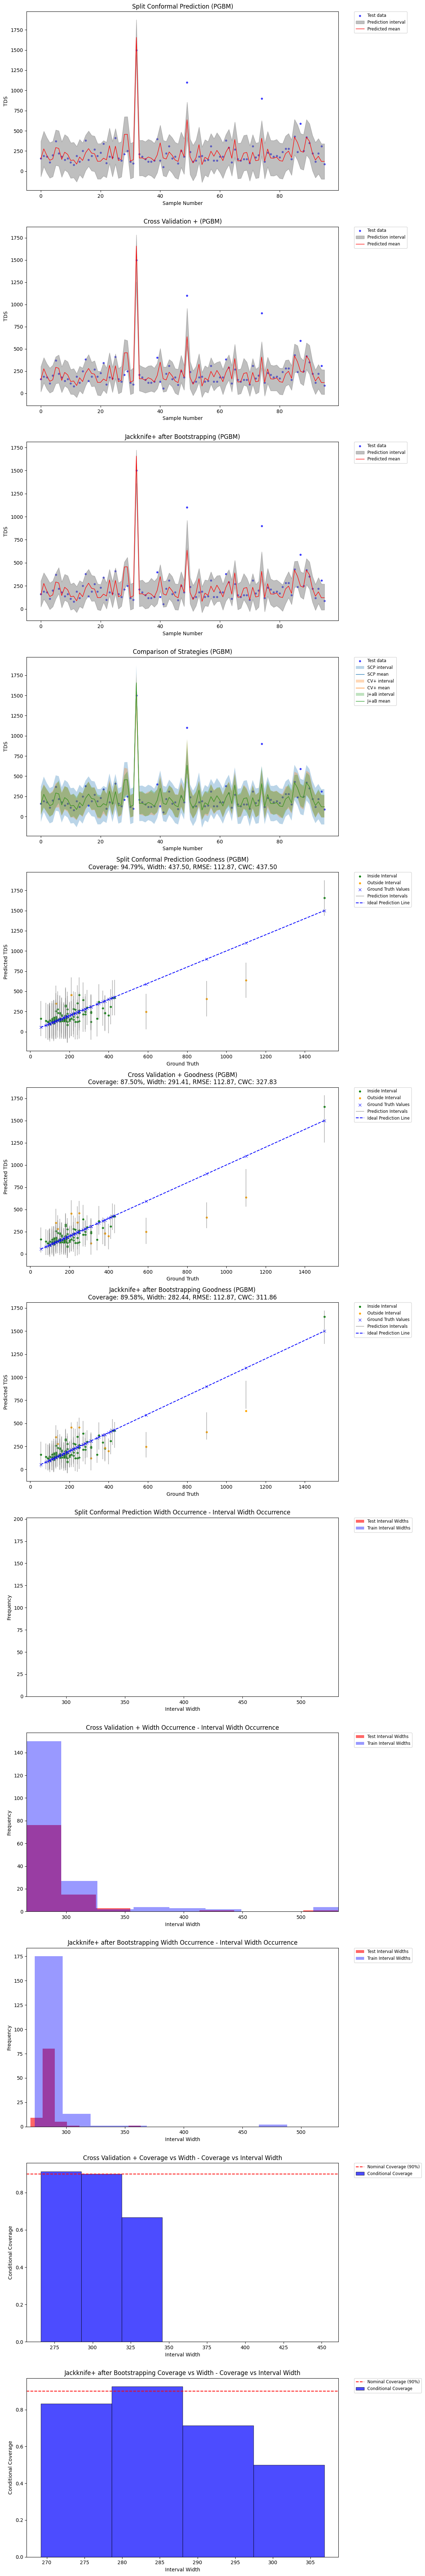

In [48]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax



def conformal_predictions_MAPIE_PGBM(
    model_class,
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name,
    excel_file_path
):
    SEED = 123
    np.random.seed(SEED)
    MISCOVERAGE = ALPHA  # FIX M4: was 0.05
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)

    # Convert y_test to a NumPy array if it has to_numpy
    y_test_np = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test

    # Map method names to descriptive labels
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }

    # Corresponding parameters for each strategy
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Create a base estimator object for each strategy
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    # Fit & predict using MapieRegressor for each strategy
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)


    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred)
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the intervals and predictions for each strategy
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names)*3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(12, 6 * n_figs))
    plot_index = 0

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                            color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red',
                                    label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Comparison subplot (moved after individual strategy plots)
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                        alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name],
                                label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1


    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1


    fig.tight_layout()

    # Save plots to Excel
    # Save plots to Excel
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        sheet_name = 'conformal_predictions_MAPIE'
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        #NEW: Save all predictions/intervals to one worksheet
        all_rows = []
        # Always use y_test_np for consistent array-ness
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = ((y_test_np >= ymin_np) & (y_test_np <= ymax_np)).astype(int)
            residual_np = y_test_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_test_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np,
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet2 = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet2.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet2.cell(row=i+2, column=j, value=float(value) if isinstance(value, np.generic) else value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))



# Example call (assuming best_params, X_train, y_train, X_test, y_test are defined elsewhere)
conformal_predictions_MAPIE_PGBM(
    model_class=PGBMWrapper,
    best_params=best_params,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="PGBM",
    excel_file_path="./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx"
)

In [49]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC_PGBM(
    X_train,
    y_train,
    X_test,
    y_test,
    best_scores_autosampler,
    model_class,
    excel_file_path=None,
    model_params=None,
    alpha=ALPHA  # FIX M4: was 0.1
):
    if model_params is None:
        if model_class.__name__ == 'PGBMWrapper':
            model_params = get_best_model_params(best_scores_autosampler, 'PGBM')
        else:
            model_params = {}

    # Initialize model
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    # Convert to NumPy arrays if needed
    y_train_np = y_train.to_numpy() if isinstance(y_train, pd.Series) else y_train
    model.fit(X_train, y_train_np)

    y_test_np = y_test.to_numpy() if isinstance(y_test, pd.Series) else y_test

    def evaluate_cp(X_test_eval, y_test_eval, model_cp, alpha_val):
        X_test_np = X_test_eval.to_numpy() if isinstance(X_test_eval, pd.DataFrame) else np.array(X_test_eval)
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test_np, alpha=alpha_val)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test_eval, y_pred_lower, y_pred_upper)
        return y_pred, y_pred_lower, y_pred_upper, sharpness, coverage

    # Base predictor setup
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train_np, fit_ratio=0.5)

    y_pred_sc, y_lower_sc, y_upper_sc, sharpness_sc, coverage_sc = evaluate_cp(X_test, y_test_np, splitcp, alpha)

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train_np)
    y_pred, y_lower_cv, y_upper_cv, sharpness_cv, coverage_cv = evaluate_cp(X_test, y_test_np, cvplus, alpha)

    # CQR
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train_np, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_lower_cqr, y_upper_cqr, sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test_np, cqr, alpha)
    y_pred_cqr = 0.5 * (y_lower_cqr + y_upper_cqr)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness_sc:.3f}")
    print(f"SplitCP - Average coverage: {coverage_sc*100:.3f}%")
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cv:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cv*100:.3f}%")
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")


    # Plotting
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    sample_indices = np.arange(len(y_test_np))

    # Plot results for each method
    for idx, (y_pred, y_lower, y_upper, title) in enumerate([
        (y_pred_sc, y_lower_sc, y_upper_sc, 'SplitCP'),
        (y_pred_sc, y_lower_cv, y_upper_cv, 'CVPlus'),
        (y_pred_cqr, y_lower_cqr, y_upper_cqr, 'CQR')
    ]):
        axs[idx].scatter(sample_indices, y_test_np, label='True', color='blue', s=10, alpha=0.7)
        axs[idx].fill_between(sample_indices, y_lower, y_upper, color='gray', alpha=0.5, label='Prediction interval')
        axs[idx].plot(sample_indices, y_pred, color='red', label='Predicted mean', linewidth=1)
        axs[idx].set_title(f'{title}: Prediction Intervals with Conformal Prediction')
        axs[idx].set_xlabel('Sample Number')
        axs[idx].set_ylabel(f'{TARGET_LABEL}')
        axs[idx].legend(fontsize='small')

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_sc).reshape(-1),
        'SplitCP_lower': np.asarray(y_lower_sc).reshape(-1),
        'SplitCP_upper': np.asarray(y_upper_sc).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_sc).reshape(-1),
        'CVPlus_lower': np.asarray(y_lower_cv).reshape(-1),
        'CVPlus_upper': np.asarray(y_upper_cv).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

# Example usage (assuming X_train, y_train, X_test, y_test, best_scores_autosampler exist):
conformal_predictions_PUNCC_PGBM(
    X_train, y_train,
    X_test, y_test,
    best_scores_autosampler=best_scores_autosampler,
    model_class=PGBMWrapper,
    excel_file_path="./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx",
    alpha=0.1
)


Training on CPU
Estimator 0/100, Train metric: 272.0730
Estimator 1/100, Train metric: 260.4306
Estimator 2/100, Train metric: 249.5487
Estimator 3/100, Train metric: 239.3290
Estimator 4/100, Train metric: 229.7705
Estimator 5/100, Train metric: 220.8012
Estimator 6/100, Train metric: 212.4063
Estimator 7/100, Train metric: 204.5448
Estimator 8/100, Train metric: 197.0444
Estimator 9/100, Train metric: 190.0085
Estimator 10/100, Train metric: 183.3679


Estimator 11/100, Train metric: 177.1315
Estimator 12/100, Train metric: 171.2754
Estimator 13/100, Train metric: 165.7105
Estimator 14/100, Train metric: 160.5106
Estimator 15/100, Train metric: 155.6174
Estimator 16/100, Train metric: 150.9492
Estimator 17/100, Train metric: 146.5276
Estimator 18/100, Train metric: 142.3985
Estimator 19/100, Train metric: 138.4901
Estimator 20/100, Train metric: 134.7193
Estimator 21/100, Train metric: 131.1131
Estimator 22/100, Train metric: 127.7327
Estimator 23/100, Train metric: 124.5207


Estimator 24/100, Train metric: 121.4783
Estimator 25/100, Train metric: 118.5194
Estimator 26/100, Train metric: 115.7612
Estimator 27/100, Train metric: 112.9345
Estimator 28/100, Train metric: 110.2707
Estimator 29/100, Train metric: 107.8487
Estimator 30/100, Train metric: 105.6156
Estimator 31/100, Train metric: 103.4932
Estimator 32/100, Train metric: 101.3059
Estimator 33/100, Train metric: 99.2535
Estimator 34/100, Train metric: 97.3164
Estimator 35/100, Train metric: 95.4440
Estimator 36/100, Train metric: 93.6803


Estimator 37/100, Train metric: 92.0293
Estimator 38/100, Train metric: 90.4265
Estimator 39/100, Train metric: 88.8943
Estimator 40/100, Train metric: 87.4100
Estimator 41/100, Train metric: 85.9410
Estimator 42/100, Train metric: 84.5816
Estimator 43/100, Train metric: 83.2309
Estimator 44/100, Train metric: 81.9256
Estimator 45/100, Train metric: 80.6894
Estimator 46/100, Train metric: 79.4676
Estimator 47/100, Train metric: 78.3253
Estimator 48/100, Train metric: 77.2435
Estimator 49/100, Train metric: 76.0672
Estimator 50/100, Train metric: 75.0705


Estimator 51/100, Train metric: 74.0627
Estimator 52/100, Train metric: 73.1462
Estimator 53/100, Train metric: 72.1820
Estimator 54/100, Train metric: 71.2539
Estimator 55/100, Train metric: 70.3354
Estimator 56/100, Train metric: 69.4053
Estimator 57/100, Train metric: 68.5664
Estimator 58/100, Train metric: 67.7062
Estimator 59/100, Train metric: 66.9193
Estimator 60/100, Train metric: 66.0859
Estimator 61/100, Train metric: 65.3456
Estimator 62/100, Train metric: 64.6331
Estimator 63/100, Train metric: 63.9526
Estimator 64/100, Train metric: 63.2129


Estimator 65/100, Train metric: 62.5303
Estimator 66/100, Train metric: 61.9184
Estimator 67/100, Train metric: 61.2744
Estimator 68/100, Train metric: 60.6432
Estimator 69/100, Train metric: 60.0452
Estimator 70/100, Train metric: 59.5317
Estimator 71/100, Train metric: 59.0469
Estimator 72/100, Train metric: 58.5170
Estimator 73/100, Train metric: 58.0346
Estimator 74/100, Train metric: 57.5724
Estimator 75/100, Train metric: 57.1575
Estimator 76/100, Train metric: 56.6305
Estimator 77/100, Train metric: 56.1590
Estimator 78/100, Train metric: 55.7049


... (64 outputs left out)

Estimator 67/100, Train metric: 74.0880
Estimator 68/100, Train metric: 73.1279
Estimator 69/100, Train metric: 72.2228
Estimator 70/100, Train metric: 71.2812
Estimator 71/100, Train metric: 70.4297
Estimator 72/100, Train metric: 69.5813
Estimator 73/100, Train metric: 68.7584
Estimator 74/100, Train metric: 67.9323
Estimator 75/100, Train metric: 67.1590
Estimator 76/100, Train metric: 66.4054
Estimator 77/100, Train metric: 65.6715
Estimator 78/100, Train metric: 64.9408
Estimator 79/100, Train metric: 64.2530


Estimator 80/100, Train metric: 63.5929
Estimator 81/100, Train metric: 62.9719
Estimator 82/100, Train metric: 62.3569
Estimator 83/100, Train metric: 61.7680
Estimator 84/100, Train metric: 61.1645
Estimator 85/100, Train metric: 60.5856
Estimator 86/100, Train metric: 60.0548
Estimator 87/100, Train metric: 59.5388
Estimator 88/100, Train metric: 59.0451
Estimator 89/100, Train metric: 58.5743
Estimator 90/100, Train metric: 58.1001
Estimator 91/100, Train metric: 57.6634
Estimator 92/100, Train metric: 57.2281
Estimator 93/100, Train metric: 56.8215


Estimator 94/100, Train metric: 56.4132
Estimator 95/100, Train metric: 55.9964
Estimator 96/100, Train metric: 55.6171
Estimator 97/100, Train metric: 55.2761
Estimator 98/100, Train metric: 54.9140
Estimator 99/100, Train metric: 54.5997


SplitCP - Average prediction intervals width (sharpness): 389.797
SplitCP - Average coverage: 94.792%
CVPlus - Average prediction intervals width (sharpness): 317.178
CVPlus - Average coverage: 94.792%
CQR - Average prediction intervals width (sharpness): 324.211
CQR - Average coverage: 91.667%


In [50]:
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, PGBMWrapper, best_params,"./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx", "PGBM Prediction Intervals")

Training on CPU
Estimator 0/100, Train metric: 272.0730
Estimator 1/100, Train metric: 260.4306
Estimator 2/100, Train metric: 249.5487
Estimator 3/100, Train metric: 239.3290
Estimator 4/100, Train metric: 229.7705
Estimator 5/100, Train metric: 220.8012
Estimator 6/100, Train metric: 212.4063
Estimator 7/100, Train metric: 204.5448
Estimator 8/100, Train metric: 197.0444
Estimator 9/100, Train metric: 190.0085


Estimator 10/100, Train metric: 183.3679
Estimator 11/100, Train metric: 177.1315
Estimator 12/100, Train metric: 171.2754
Estimator 13/100, Train metric: 165.7105
Estimator 14/100, Train metric: 160.5106
Estimator 15/100, Train metric: 155.6174
Estimator 16/100, Train metric: 150.9492
Estimator 17/100, Train metric: 146.5276
Estimator 18/100, Train metric: 142.3985
Estimator 19/100, Train metric: 138.4901
Estimator 20/100, Train metric: 134.7193
Estimator 21/100, Train metric: 131.1131


Estimator 22/100, Train metric: 127.7327
Estimator 23/100, Train metric: 124.5207
Estimator 24/100, Train metric: 121.4783
Estimator 25/100, Train metric: 118.5194
Estimator 26/100, Train metric: 115.7612
Estimator 27/100, Train metric: 112.9345
Estimator 28/100, Train metric: 110.2707
Estimator 29/100, Train metric: 107.8487
Estimator 30/100, Train metric: 105.6156
Estimator 31/100, Train metric: 103.4932
Estimator 32/100, Train metric: 101.3059
Estimator 33/100, Train metric: 99.2535


Estimator 34/100, Train metric: 97.3164
Estimator 35/100, Train metric: 95.4440
Estimator 36/100, Train metric: 93.6803
Estimator 37/100, Train metric: 92.0293
Estimator 38/100, Train metric: 90.4265
Estimator 39/100, Train metric: 88.8943
Estimator 40/100, Train metric: 87.4100
Estimator 41/100, Train metric: 85.9410
Estimator 42/100, Train metric: 84.5816
Estimator 43/100, Train metric: 83.2309
Estimator 44/100, Train metric: 81.9256
Estimator 45/100, Train metric: 80.6894
Estimator 46/100, Train metric: 79.4676


Estimator 47/100, Train metric: 78.3253
Estimator 48/100, Train metric: 77.2435
Estimator 49/100, Train metric: 76.0672
Estimator 50/100, Train metric: 75.0705
Estimator 51/100, Train metric: 74.0627
Estimator 52/100, Train metric: 73.1462
Estimator 53/100, Train metric: 72.1820
Estimator 54/100, Train metric: 71.2539
Estimator 55/100, Train metric: 70.3354
Estimator 56/100, Train metric: 69.4053
Estimator 57/100, Train metric: 68.5664
Estimator 58/100, Train metric: 67.7062
Estimator 59/100, Train metric: 66.9193


Estimator 60/100, Train metric: 66.0859
Estimator 61/100, Train metric: 65.3456
Estimator 62/100, Train metric: 64.6331
Estimator 63/100, Train metric: 63.9526
Estimator 64/100, Train metric: 63.2129
Estimator 65/100, Train metric: 62.5303
Estimator 66/100, Train metric: 61.9184
Estimator 67/100, Train metric: 61.2744
Estimator 68/100, Train metric: 60.6432
Estimator 69/100, Train metric: 60.0452
Estimator 70/100, Train metric: 59.5317
Estimator 71/100, Train metric: 59.0469


... (365 outputs left out)

Estimator 48/100, Train metric: 58.6130
Estimator 49/100, Train metric: 57.5579
Estimator 50/100, Train metric: 56.4867
Estimator 51/100, Train metric: 55.4801
Estimator 52/100, Train metric: 54.5552
Estimator 53/100, Train metric: 53.6335
Estimator 54/100, Train metric: 52.7171
Estimator 55/100, Train metric: 51.8106
Estimator 56/100, Train metric: 50.9573
Estimator 57/100, Train metric: 50.1283
Estimator 58/100, Train metric: 49.3432
Estimator 59/100, Train metric: 48.5963
Estimator 60/100, Train metric: 47.8659


Estimator 61/100, Train metric: 47.1174
Estimator 62/100, Train metric: 46.3764
Estimator 63/100, Train metric: 45.7452
Estimator 64/100, Train metric: 45.0658
Estimator 65/100, Train metric: 44.4354
Estimator 66/100, Train metric: 43.8149
Estimator 67/100, Train metric: 43.2382
Estimator 68/100, Train metric: 42.6793
Estimator 69/100, Train metric: 42.0949
Estimator 70/100, Train metric: 41.6078
Estimator 71/100, Train metric: 41.0479
Estimator 72/100, Train metric: 40.5479
Estimator 73/100, Train metric: 40.0301


Estimator 74/100, Train metric: 39.5217
Estimator 75/100, Train metric: 39.0037
Estimator 76/100, Train metric: 38.5188
Estimator 77/100, Train metric: 38.0502
Estimator 78/100, Train metric: 37.6009
Estimator 79/100, Train metric: 37.1642
Estimator 80/100, Train metric: 36.6759
Estimator 81/100, Train metric: 36.2670
Estimator 82/100, Train metric: 35.8140
Estimator 83/100, Train metric: 35.4144
Estimator 84/100, Train metric: 35.0352
Estimator 85/100, Train metric: 34.6729
Estimator 86/100, Train metric: 34.2190


Estimator 87/100, Train metric: 33.8688
Estimator 88/100, Train metric: 33.5333
Estimator 89/100, Train metric: 33.1640
Estimator 90/100, Train metric: 32.7588
Estimator 91/100, Train metric: 32.4552
Estimator 92/100, Train metric: 32.1407
Estimator 93/100, Train metric: 31.8137
Estimator 94/100, Train metric: 31.4889
Estimator 95/100, Train metric: 31.1407
Estimator 96/100, Train metric: 30.8226
Estimator 97/100, Train metric: 30.5196
Estimator 98/100, Train metric: 30.1963
Estimator 99/100, Train metric: 29.8368


# **Conformal Predictions with TabNet**

In [51]:
best_params = get_best_model_params(best_scores_autosampler, 'TabNet')
print(best_params)

{'n_d': 16, 'n_a': 16, 'n_steps': 10, 'gamma': 1.5, 'lambda_sparse': 0.01, 'optimizer_params': {'lr': 0.02}, 'mask_type': 'sparsemax', 'n_shared': 1, 'n_independent': 2, 'scheduler_params': {'step_size': 10, 'gamma': 0.9}, 'scheduler_fn': <class 'torch.optim.lr_scheduler.StepLR'>, 'seed': 42, 'verbose': 0}


In [52]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class TabNetRegressorCP(TabNetRegressor):
    def fit(self, X, y, *args, **kwargs):
        y_ = np.array(y)
        if y_.ndim == 1:
            y_ = y_.reshape(-1, 1)
        return super().fit(X, y_, *args, **kwargs)
    def predict(self, X, *args, **kwargs):
        preds = super().predict(X, *args, **kwargs)
        return preds.flatten()
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.mean((y_arr >= int_pred[strat_name][:, 0]) & (y_arr <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.sqrt(mean_squared_error(y_arr, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        y_arr = np.array(y_test)
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_arr[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) &
                                           (y_arr[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan)
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages
class visualize:
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        y_true_np = np.array(y_true).ravel()
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')
        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)],
                 linestyle='--', color='blue', label='Ideal Prediction Line')
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')
        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()
        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]
        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE_tabnet(
    model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path
):
    is_tabnet = ("TabNet" in model_name or "TabNet" in model_class.__name__)

    # Remove 'verbose' if present to avoid TypeError in TabNet
    if isinstance(best_params, dict) and "verbose" in best_params:
        best_params = dict(best_params) # make a copy!
        best_params.pop("verbose", None)

    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    MISCOVERAGE = ALPHA  # FIX M4
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 5},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {}

    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(np.array(X_train), np.array(y_train))
        y_pred_raw, int_pred_raw = mapie.predict(np.array(X_test), alpha=MISCOVERAGE)
        y_pred[strat_name] = y_pred_raw.flatten()
        int_pred[strat_name] = np.array(int_pred_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train_raw, int_pred_train_raw = mapie.predict(np.array(X_train), alpha=MISCOVERAGE)
        y_pred_train[strat_name] = y_pred_train_raw.flatten()
        int_pred_train[strat_name] = np.array(int_pred_train_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # All metric calls now use np.array(y_test)
    coverages = validate.coverage(int_pred, np.array(y_test))
    widths = validate.width(int_pred)
    rmse_vals = validate.rmse(y_pred, np.array(y_test))
    cwc_vals = validate.cwc(int_pred, np.array(y_test), MISCOVERAGE)

    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            rmse = rmse_vals[strat_name]
            interval_width = widths[strat_name]
            coverage = coverages[strat_name]
            cwc = cwc_vals[strat_name]
            ssc = np.mean((np.array(y_test) - y_pred[strat_name])**2 +
                          (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)
            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}\n")

    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS = N_BINS  # FIX D4
    n_figs = len(strategies_names) * 3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))
    plot_index = 0

    # Individual strategy plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)
    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()
            axs[plot_index] = visualize.goodness(
                np.array(y_test), y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})',
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages = validate.cond_coverage(int_pred, np.array(y_test), num_bins=NUM_BINS)
    for _strat in _strategies:
        axs[plot_index] = visualize.coverage_by_width(
            np.array(y_test), int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = f'conformal_predictions_MAPIE_{model_name}'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        # Tabular export
        all_rows = []
        y_true_np = np.array(y_test).ravel()
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np
            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)
        all_pred_sheet_name = 'all_pred_values_' + model_name
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1
        worksheet = workbook.create_sheet(title=all_pred_sheet_name)
        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()


conformal_predictions_MAPIE_tabnet(
    TabNetRegressorCP,        # <------ use the wrapper here!
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    "TabNet",
    "./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx"
)

epoch 0  | loss: 147205.89062|  0:00:00s
epoch 1  | loss: 146168.70312|  0:00:00s
epoch 2  | loss: 145506.59375|  0:00:00s
epoch 3  | loss: 144732.46875|  0:00:00s


epoch 4  | loss: 143966.23438|  0:00:00s
epoch 5  | loss: 142869.23438|  0:00:00s
epoch 6  | loss: 142314.89062|  0:00:00s


epoch 7  | loss: 141496.45312|  0:00:00s
epoch 8  | loss: 140193.60938|  0:00:00s
epoch 9  | loss: 139740.28125|  0:00:00s
epoch 10 | loss: 138751.17188|  0:00:00s


epoch 11 | loss: 137579.70312|  0:00:00s
epoch 12 | loss: 136241.85938|  0:00:00s
epoch 13 | loss: 135009.23438|  0:00:01s
epoch 14 | loss: 133459.67188|  0:00:01s


epoch 15 | loss: 132005.82812|  0:00:01s
epoch 16 | loss: 130261.00781|  0:00:01s
epoch 17 | loss: 128694.34375|  0:00:01s
epoch 18 | loss: 126927.15625|  0:00:01s


epoch 19 | loss: 125784.32031|  0:00:01s
epoch 20 | loss: 124641.11719|  0:00:01s
epoch 21 | loss: 122956.625|  0:00:01s


... (1,529 outputs left out)

epoch 91 | loss: 5391.05664|  0:00:05s
epoch 92 | loss: 5161.62939|  0:00:05s
epoch 93 | loss: 5123.99902|  0:00:05s
epoch 94 | loss: 5043.15869|  0:00:05s


epoch 95 | loss: 5031.93994|  0:00:06s
epoch 96 | loss: 4904.07275|  0:00:06s
epoch 97 | loss: 4863.48926|  0:00:06s
epoch 98 | loss: 4898.8208|  0:00:06s


epoch 99 | loss: 4834.19043|  0:00:06s


Strategy: Split Conformal Prediction
  RMSE: 116.8188
  Interval Width: 566.1862
  Coverage: 96.88%
  CWC: 566.1862
  SSC: 334213.3858

Strategy: Cross Validation +
  RMSE: 116.8188
  Interval Width: 393.3405
  Coverage: 95.83%
  CWC: 393.3405
  SSC: 194824.3033

Strategy: Jackknife+ after Bootstrapping
  RMSE: 116.8188
  Interval Width: 280.4192
  Coverage: 87.50%
  CWC: 315.4716
  SSC: 92486.6609



In [53]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

def conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Get best parameters if not supplied
    if model_params is None:
        model_params = get_best_model_params(best_scores_autosampler, 'TabNet')
        if "verbose" in model_params:
            model_params = dict(model_params)
            model_params.pop("verbose", None)

    model_class = TabNetRegressorCP

    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing TabNet: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_te, y_te, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_te, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(np.array(y_te), y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Base predictor
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    picp_splitcp = np.mean((np.array(y_test).ravel() >= y_pred_lower_splitcp) &
                           (np.array(y_test).ravel() <= y_pred_upper_splitcp))
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")
    print(f"SplitCP - PICP: {picp_splitcp*100:.3f}%")

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness_cvplus, coverage_cvplus = evaluate_cp(X_test, y_test, cvplus, alpha)
    picp_cvplus = np.mean((np.array(y_test).ravel() >= y_pred_lower_cvplus) &
                          (np.array(y_test).ravel() <= y_pred_upper_cvplus))
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cvplus:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cvplus*100:.3f}%")
    print(f"CVPlus - PICP: {picp_cvplus*100:.3f}%\n")

    # CQR
    from sklearn.model_selection import train_test_split
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test, cqr, alpha)
    picp_cqr = np.mean((np.array(y_test).ravel() >= y_pred_lower_cqr) &
                       (np.array(y_test).ravel() <= y_pred_upper_cqr))
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")
    print(f"CQR - PICP: {picp_cqr*100:.3f}%\n")

    # Plot
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    arr_y_test = np.array(y_test).ravel()
    axs[0].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(arr_y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[1].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[2].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(arr_y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export ---
    results_dict = {
        'SplitCP_true': arr_y_test.reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': arr_y_test.reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': arr_y_test.reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC_TabNet')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_TabNet_values')

    plt.close(fig)


conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path="./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    model_params=best_params  # your best params for TabNet
)

SplitCP - Average prediction intervals width (sharpness): 515.833
SplitCP - Average coverage: 93.750%
SplitCP - PICP: 93.750%


CVPlus - Average prediction intervals width (sharpness): 416.205
CVPlus - Average coverage: 96.875%
CVPlus - PICP: 96.875%



CQR - Average prediction intervals width (sharpness): 577.517
CQR - Average coverage: 96.875%
CQR - PICP: 96.875%



In [54]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params,
    excel_file_path=None,
    suptitle: str = "TabNet Prediction Intervals"
) -> None:
    # Use wrapper for TabNet
    model_cls = TabNetRegressorCP

    # Train model with MAPIE
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [np.array(y_train).min(), np.array(y_train).max()],
            [np.array(y_train).min(), np.array(y_train).max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        np.array(y_train).ravel(),
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        np.array(y_test).ravel(),
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        # Use a fresh model each time (sklearn style)
        mapie = MapieRegressor(model_cls(**model_params), **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_2')

    plt.close(fig)

# Helper method for Excel plotting export
def save_plot_to_excel(fig, excel_file_path, sheet_name):
    import io
    from openpyxl import load_workbook
    from openpyxl.drawing.image import Image
    from PIL import Image as PILImage
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PILImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)
        worksheet.add_image(img, 'A1')
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))


prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params=best_params,
    excel_file_path="./drive/MyDrive/Regression/streamflow_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    suptitle="TabNet Prediction Intervals"
)